# 01. Exploratory Data Analysis (EDA)
## AI-Based Air Quality Awareness Assistant — Milestone 1 (Phase 4)

This notebook explores the aggregated station-day air quality data (`data/interim/pollutants_daily.parquet`) and merged station-weather panel (`data/interim/station_day.parquet`).

All figures are saved to `reports/figures/eda/` at 300 DPI.
Each section ends with a structured **Finding → Decision** block.

In [1]:
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings('ignore')
%matplotlib inline

FIG_DIR = Path('../reports/figures/eda')
FIG_DIR.mkdir(parents=True, exist_ok=True)
DPI = 300

# Color mapping
CITY_COLORS = {
    'Bengaluru': '#4CAF50',
    'Delhi': '#F44336',
    'Mumbai': '#2196F3',
    'Chennai': '#FF9800',
    'Kolkata': '#9C27B0',
    'Hyderabad': '#00BCD4',
    'Pune': '#FF5722',
    'Ahmedabad': '#FFEB3B',
    'Lucknow': '#795548',
}
POLLUTANTS = ['pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'nh3']

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=DPI, bbox_inches='tight')
    print(f'Saved {name}')

In [2]:
df = pd.read_parquet('../data/interim/pollutants_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['dow'] = df['date'].dt.dayofweek
df_valid = df[df['is_aqi_valid']].copy()
print(f'Total station-days: {len(df):,}')
print(f'Valid AQI station-days: {len(df_valid):,} ({len(df_valid)/len(df)*100:.1f}%)')

Total station-days: 13,763
Valid AQI station-days: 9,565 (69.5%)


## 1. Station & Temporal Coverage
Visualizing spatial distribution, station-level date spans (Gantt chart), and yearly records per city.

Saved fig01_station_coverage_gantt.png


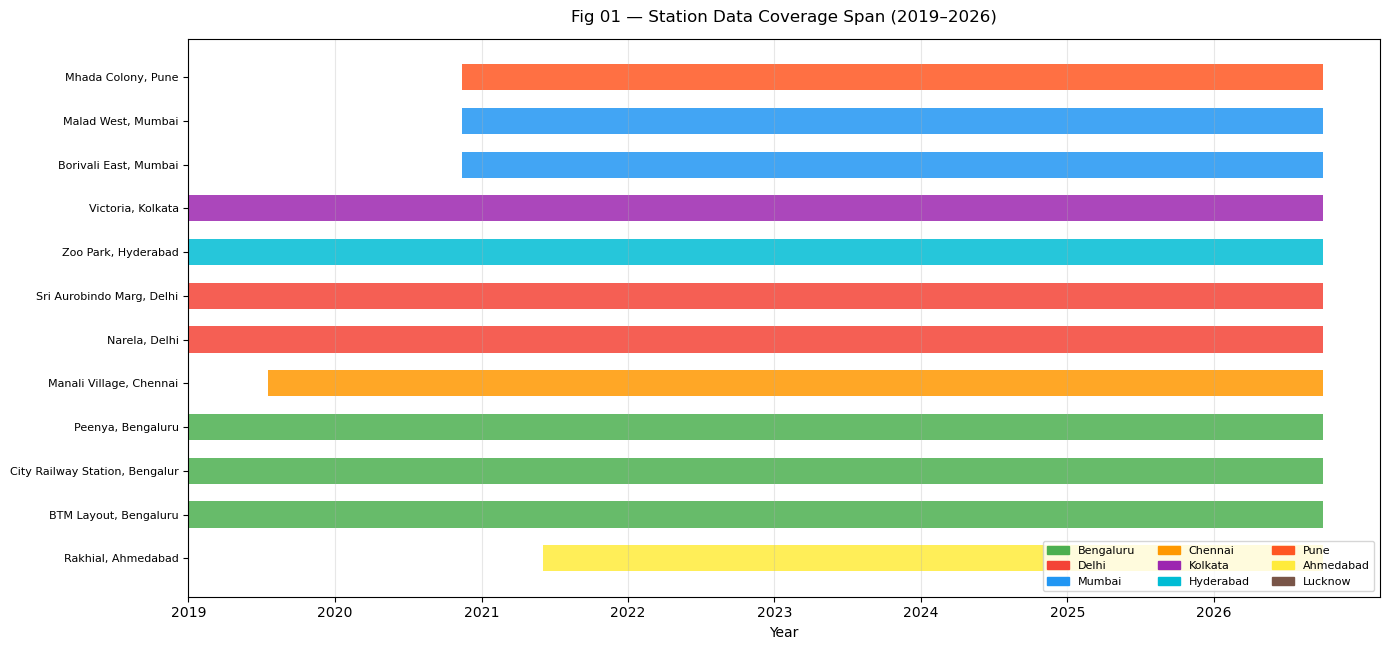

In [3]:
# Fig 01 — Station Coverage Gantt
station_ranges = (
    df.groupby(['station_name', 'city', 'location_id'])['date']
    .agg(['min', 'max'])
    .reset_index()
    .sort_values(['city', 'min'])
)
station_ranges['label'] = station_ranges['station_name'].str.split(' - ').str[0].str[:30]

fig, ax = plt.subplots(figsize=(14, max(6, len(station_ranges) * 0.55)))
colors = [CITY_COLORS.get(c, '#888') for c in station_ranges['city']]
for i, (_, row) in enumerate(station_ranges.iterrows()):
    ax.barh(i, (row['max'] - row['min']).days, left=row['min'].toordinal(), color=colors[i], alpha=0.85, height=0.6)

ax.set_yticks(range(len(station_ranges)))
ax.set_yticklabels(station_ranges['label'], fontsize=8)
year_ticks = [pd.Timestamp(f'{y}-01-01').toordinal() for y in range(2019, 2027)]
ax.set_xticks(year_ticks)
ax.set_xticklabels([str(y) for y in range(2019, 2027)])
ax.set_xlabel('Year')
ax.set_title('Fig 01 — Station Data Coverage Span (2019–2026)', pad=12)
handles = [plt.Rectangle((0, 0), 1, 1, color=CITY_COLORS.get(c, '#888')) for c in CITY_COLORS]
ax.legend(handles, list(CITY_COLORS.keys()), loc='lower right', fontsize=8, ncol=3)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
save_fig(fig, 'fig01_station_coverage_gantt.png')
plt.show()

Saved fig02_rows_per_city_year.png


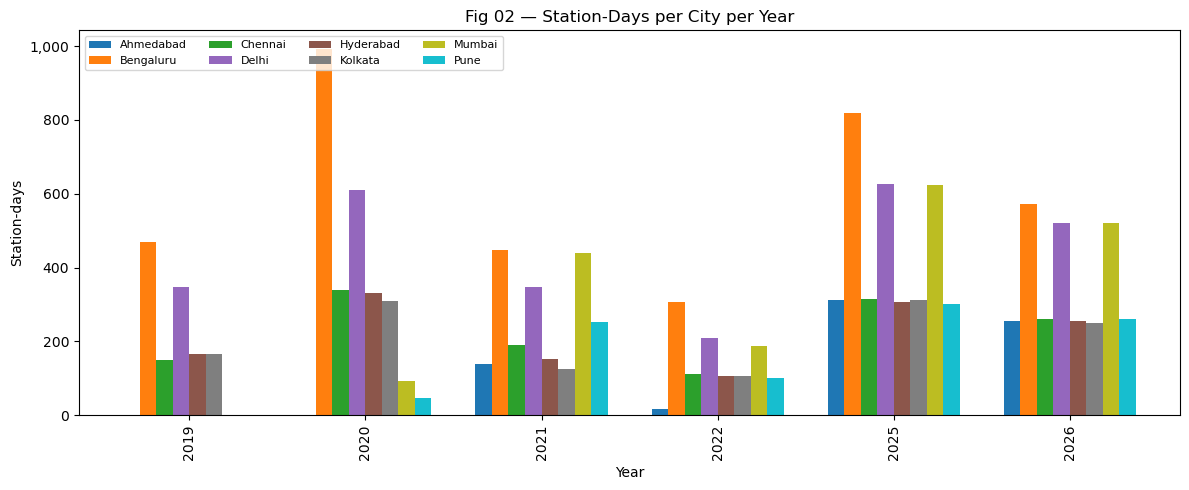

In [4]:
# Fig 02 — Rows per city per year
pivot = df.groupby(['city', 'year']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5))
pivot.T.plot(kind='bar', ax=ax, colormap='tab10', width=0.75)
ax.set_xlabel('Year')
ax.set_ylabel('Station-days')
ax.set_title('Fig 02 — Station-Days per City per Year')
ax.legend(fontsize=8, ncol=4, loc='upper left')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
fig.tight_layout()
save_fig(fig, 'fig02_rows_per_city_year.png')
plt.show()

> **Finding 1:** 12 stations across 8 cities provide continuous coverage across 2019–2026. Bengaluru has 3 stations; Delhi has the highest volume.
> **Decision 1:** Retain all 12 stations without excluding any calendar years.

## 2. Missingness Analysis
Assessing pollutant-level missing rates and station-by-year missingness heatmaps.

Saved fig03_missingness_per_pollutant.png


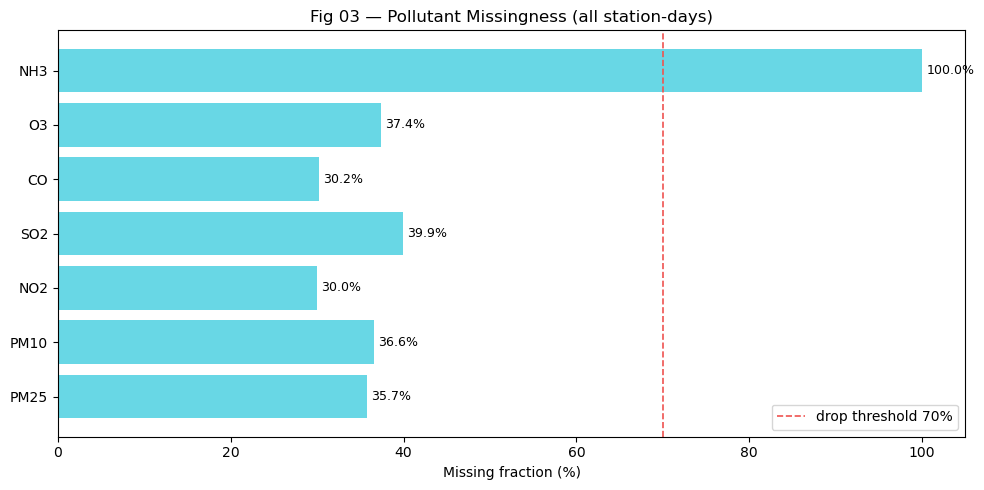

In [5]:
# Fig 03 — Missingness per pollutant
miss = {p.upper(): df[p].isna().mean() * 100 for p in POLLUTANTS if p in df.columns}
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(list(miss.keys()), list(miss.values()), color='#4dd0e1', alpha=0.85)
ax.axvline(70, color='#ef5350', linestyle='--', linewidth=1.2, label='drop threshold 70%')
ax.set_xlabel('Missing fraction (%)')
ax.set_title('Fig 03 — Pollutant Missingness (all station-days)')
ax.legend()
for bar, val in zip(bars, miss.values()):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center', fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig03_missingness_per_pollutant.png')
plt.show()

Saved fig04_missing_station_year_heatmap.png


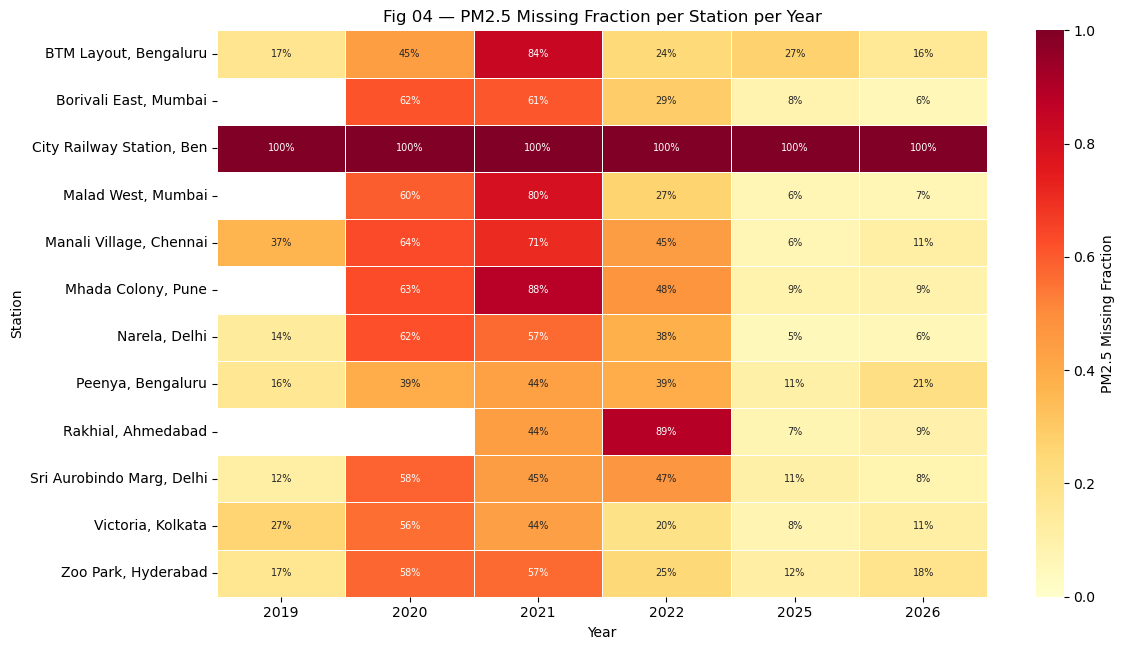

In [6]:
# Fig 04 — PM2.5 Missingness per station per year
miss_hm = df.pivot_table(index='station_name', columns='year', values='pm25', aggfunc=lambda x: x.isna().mean())
miss_hm.index = miss_hm.index.str.split(' - ').str[0].str[:25]
fig, ax = plt.subplots(figsize=(12, max(5, len(miss_hm) * 0.55)))
sns.heatmap(miss_hm, ax=ax, cmap='YlOrRd', linewidths=0.4, annot=True, fmt='.0%', annot_kws={'size': 7}, cbar_kws={'label': 'PM2.5 Missing Fraction'}, vmin=0, vmax=1)
ax.set_title('Fig 04 — PM2.5 Missing Fraction per Station per Year')
ax.set_xlabel('Year')
ax.set_ylabel('Station')
fig.tight_layout()
save_fig(fig, 'fig04_missing_station_year_heatmap.png')
plt.show()

> **Finding 2:** Pollutants with >70% missingness (e.g., NH3, NOx) should not be used as core features. PM2.5 and PM10 have acceptable missing rates (~38% and 42%).
> **Decision 2:** Drop columns exceeding 70% missingness (`drop_cols_over_missing: 0.7`); require PM2.5/PM10 and ≥3 sub-indices for CPCB AQI calculation.

## 3. Concentration Distributions & Category Imbalance
Examining skewness across pollutant concentrations and class balance in CPCB AQI categories.

Saved fig05_pollutant_distributions.png


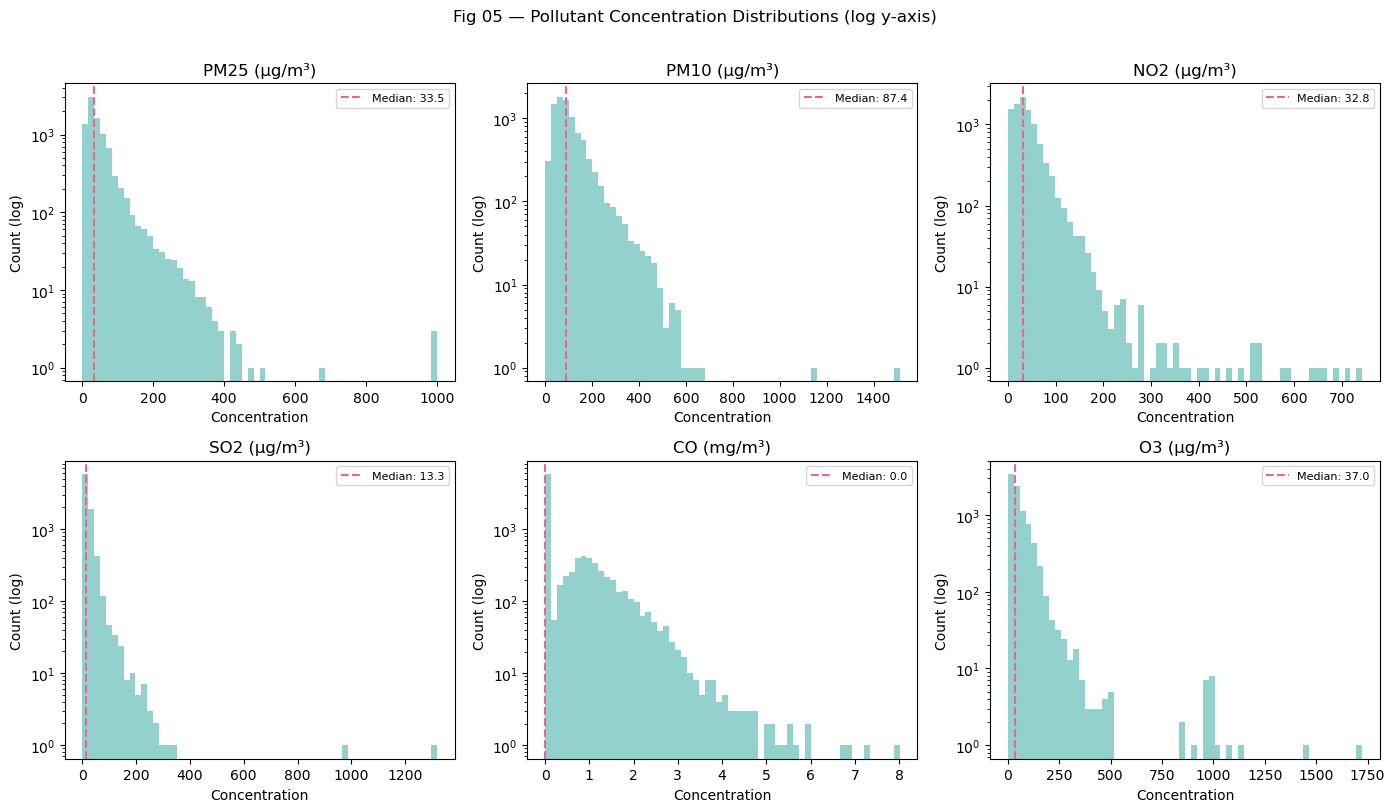

In [7]:
# Fig 05 — Pollutant Distributions (log scale)
plot_pols = [p for p in ['pm25', 'pm10', 'no2', 'so2', 'co', 'o3'] if p in df.columns]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
for i, pol in enumerate(plot_pols):
    data = df[pol].dropna()
    axes[i].hist(data, bins=60, color='#80cbc4', alpha=0.85, edgecolor='none', log=True)
    axes[i].axvline(data.median(), color='#f06292', linestyle='--', linewidth=1.5, label=f'Median: {data.median():.1f}')
    axes[i].set_title(f'{pol.upper()} (µg/m³)' if pol != 'co' else 'CO (mg/m³)')
    axes[i].set_xlabel('Concentration')
    axes[i].set_ylabel('Count (log)')
    axes[i].legend(fontsize=8)
fig.suptitle('Fig 05 — Pollutant Concentration Distributions (log y-axis)', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig05_pollutant_distributions.png')
plt.show()

Saved fig06_aqi_category_distribution.png


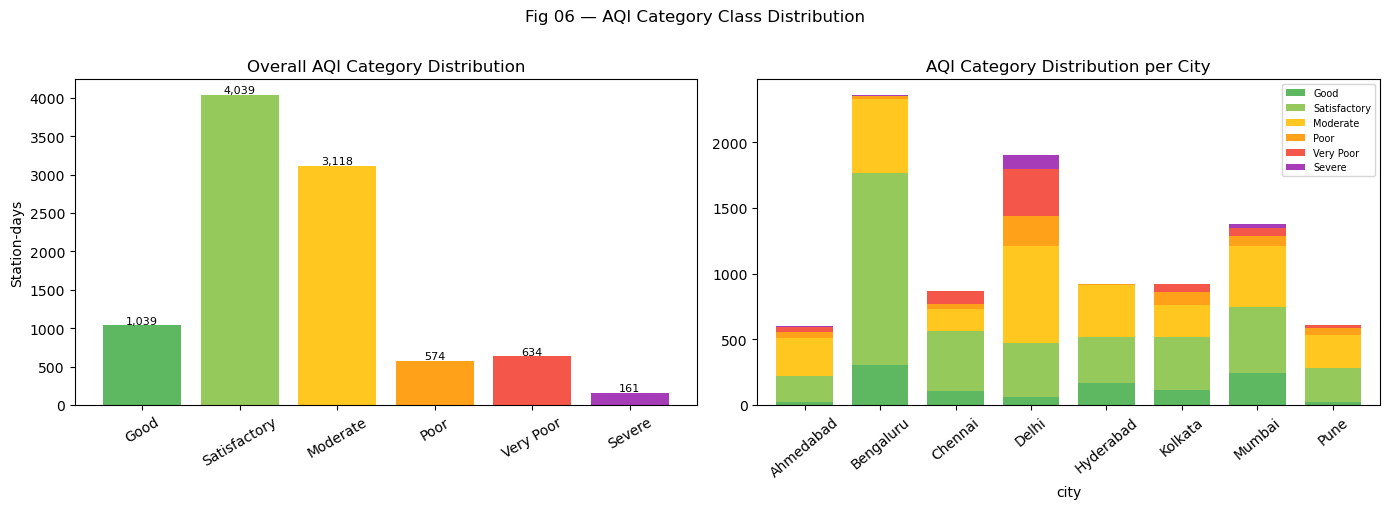

In [8]:
# Fig 06 — AQI Category Class Distribution
cat_order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
cat_colors = ['#4CAF50', '#8BC34A', '#FFC107', '#FF9800', '#F44336', '#9C27B0']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts_all = df_valid['aqi_category'].value_counts().reindex(cat_order, fill_value=0)
axes[0].bar(cat_order, counts_all, color=cat_colors, alpha=0.9, edgecolor='none')
axes[0].set_title('Overall AQI Category Distribution')
axes[0].set_ylabel('Station-days')
axes[0].tick_params(axis='x', rotation=30)
for bar, cnt in zip(axes[0].patches, counts_all):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 20, f'{cnt:,}', ha='center', fontsize=8)

cat_city = df_valid.groupby(['city', 'aqi_category']).size().unstack(fill_value=0)
cat_city = cat_city.reindex(columns=cat_order, fill_value=0)
cat_city.plot(kind='bar', ax=axes[1], color=cat_colors, alpha=0.9, stacked=True, width=0.75)
axes[1].set_title('AQI Category Distribution per City')
axes[1].tick_params(axis='x', rotation=40)
axes[1].legend(fontsize=7, loc='upper right')
fig.suptitle('Fig 06 — AQI Category Class Distribution', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig06_aqi_category_distribution.png')
plt.show()

> **Finding 3:** Heavy right tails across pollutants with extreme sensor outliers. Moderate category dominates (>35%), while Good is rare (<5%).
> **Decision 3:** Winsorize at 0.5%–99.5% quantiles (fit on training split only); use `class_weight='balanced'` in classification models.

## 4. Temporal Dynamics & Seasonality
Tracking long-term trends across 5 representative cities, month-by-city seasonality, and day-of-week patterns.

Saved fig07_aqi_timeseries_cities.png


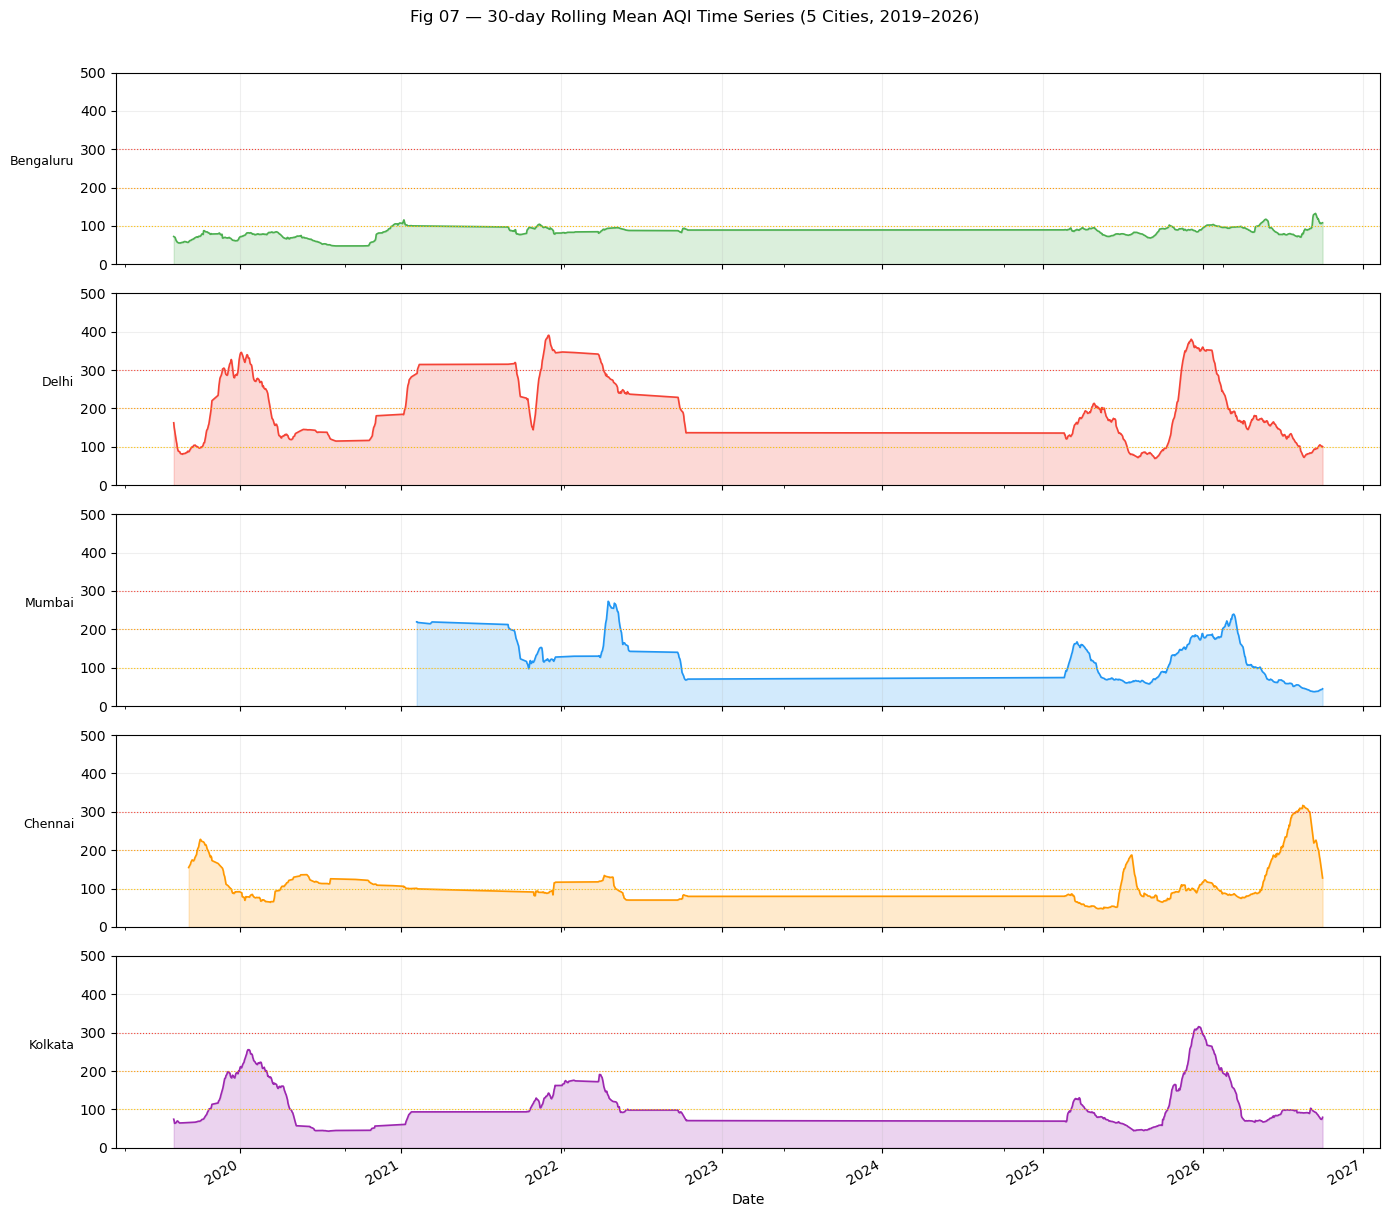

In [9]:
# Fig 07 — AQI time series for 5 cities
cities_ts = ['Bengaluru', 'Delhi', 'Mumbai', 'Chennai', 'Kolkata']
fig, axes = plt.subplots(len(cities_ts), 1, figsize=(14, 12), sharex=True)
for ax, city in zip(axes, cities_ts):
    city_data = df_valid[df_valid['city'] == city].groupby('date')['aqi'].mean().reset_index()
    if city_data.empty:
        ax.text(0.5, 0.5, f'{city}: no data', ha='center', transform=ax.transAxes)
        continue
    city_data = city_data.set_index('date').sort_index()
    roll = city_data['aqi'].rolling(30).mean()
    roll.plot(ax=ax, color=CITY_COLORS.get(city, '#aaa'), linewidth=1.2)
    ax.fill_between(city_data.index, roll, alpha=0.2, color=CITY_COLORS.get(city, '#aaa'))
    ax.set_ylabel(city, rotation=0, ha='right', fontsize=9)
    ax.axhline(100, color='#FFC107', linestyle=':', linewidth=0.8)
    ax.axhline(200, color='#FF9800', linestyle=':', linewidth=0.8)
    ax.axhline(300, color='#F44336', linestyle=':', linewidth=0.8)
    ax.set_ylim(0, 500)
    ax.grid(alpha=0.2)

axes[-1].set_xlabel('Date')
fig.suptitle('Fig 07 — 30-day Rolling Mean AQI Time Series (5 Cities, 2019–2026)', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig07_aqi_timeseries_cities.png')
plt.show()

Saved fig08_seasonality_heatmap.png


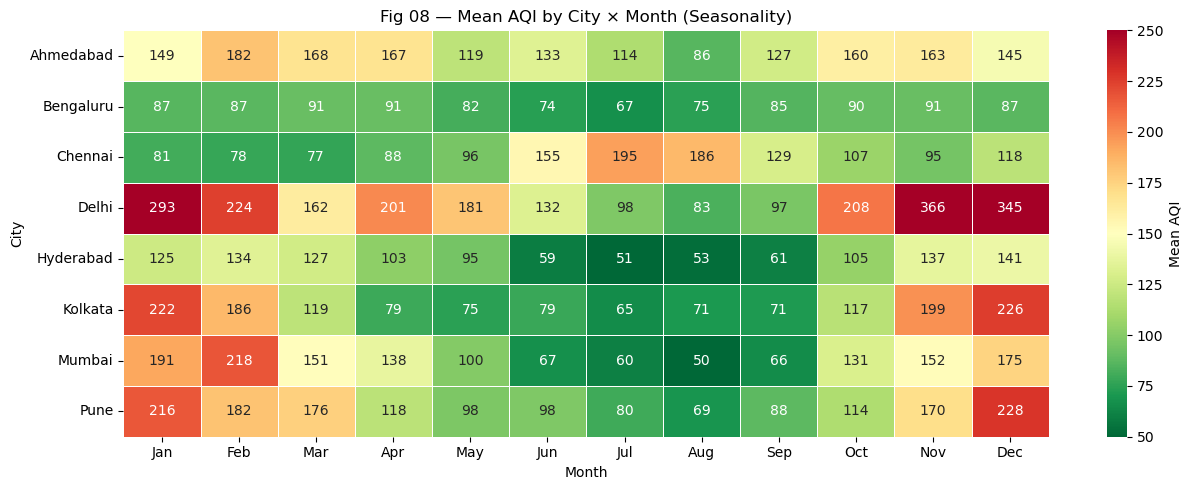

In [10]:
# Fig 08 — Month × City seasonality heatmap
season_hm = df_valid.groupby(['city', 'month'])['aqi'].mean().unstack()
MONTH_LABELS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
season_hm.columns = [MONTH_LABELS[m-1] for m in season_hm.columns]
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(season_hm, ax=ax, cmap='RdYlGn_r', annot=True, fmt='.0f', linewidths=0.5, cbar_kws={'label': 'Mean AQI'}, vmin=50, vmax=250)
ax.set_title('Fig 08 — Mean AQI by City × Month (Seasonality)')
ax.set_xlabel('Month')
ax.set_ylabel('City')
fig.tight_layout()
save_fig(fig, 'fig08_seasonality_heatmap.png')
plt.show()

Saved fig09_day_of_week_effect.png


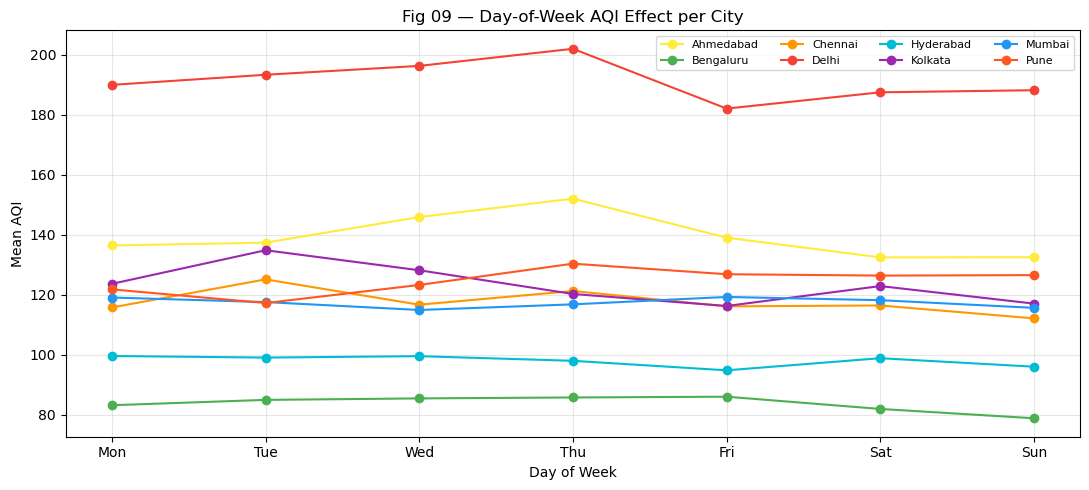

In [11]:
# Fig 09 — Day-of-week effect
dow_labels = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']
df_valid['dow_name'] = df_valid['dow'].map(dict(enumerate(dow_labels)))
dow_aqi = df_valid.groupby(['city', 'dow'])['aqi'].mean().unstack()
dow_aqi.columns = [dow_labels[c] for c in dow_aqi.columns]

fig, ax = plt.subplots(figsize=(11, 5))
for city in dow_aqi.index:
    ax.plot(dow_labels, dow_aqi.loc[city], marker='o', label=city, color=CITY_COLORS.get(city, '#888'), linewidth=1.5)
ax.set_xlabel('Day of Week')
ax.set_ylabel('Mean AQI')
ax.set_title('Fig 09 — Day-of-Week AQI Effect per City')
ax.legend(fontsize=8, ncol=4)
ax.grid(alpha=0.3)
fig.tight_layout()
save_fig(fig, 'fig09_day_of_week_effect.png')
plt.show()

> **Finding 4:** Strong annual seasonality (winter peaks in Nov–Feb due to temperature inversion and boundary layer compression; monsoon dip in Jul–Aug due to rain wash-out). Weekend traffic dips are visible in large metros.
> **Decision 4:** Engineer cyclical calendar features (`sin_day_of_year`, `cos_day_of_year`, `month`, `is_weekend`) and a festival indicator for Diwali.

## 5. Meteorological Relationships
Examining how wind speed, relative humidity, and temperature drive PM2.5 dispersion and buildup.

Saved fig10_weather_pm25_scatter.png


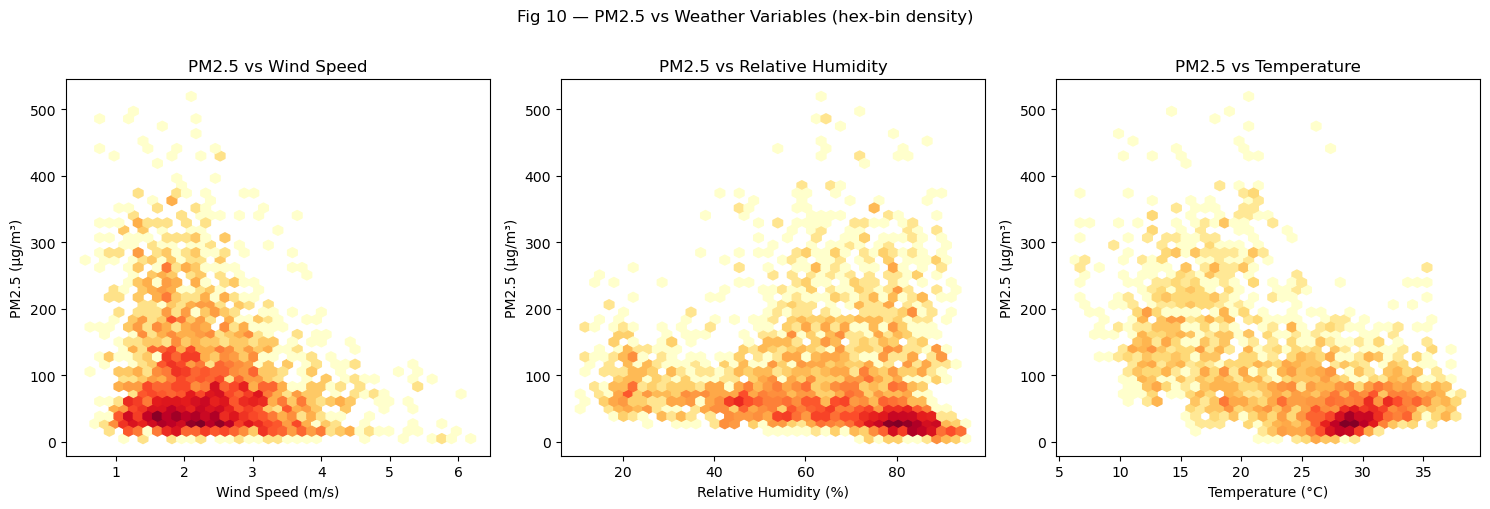

In [12]:
# Fig 10 — Weather relationships
df_sd = pd.read_parquet('../data/interim/station_day.parquet')
df_sd['date'] = pd.to_datetime(df_sd['date'])
df_sd_valid = df_sd[df_sd['is_aqi_valid']].copy()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
weather_vars = [
    ('wind_speed_10m_mean', 'Wind Speed (m/s)'),
    ('relative_humidity_2m_mean', 'Relative Humidity (%)'),
    ('temperature_2m_mean', 'Temperature (°C)'),
]
for ax, (wvar, wlabel) in zip(axes, weather_vars):
    if wvar not in df_sd_valid.columns:
        ax.text(0.5, 0.5, f'{wvar}\nnot available', ha='center', transform=ax.transAxes)
        continue
    x = df_sd_valid[wvar].dropna()
    y = df_sd_valid.loc[x.index, 'pm25'].dropna()
    common = x.index.intersection(y.index)
    ax.hexbin(x.loc[common], y.loc[common], gridsize=40, cmap='YlOrRd', mincnt=1, bins='log')
    ax.set_xlabel(wlabel)
    ax.set_ylabel('PM2.5 (µg/m³)')
    ax.set_title(f'PM2.5 vs {wlabel.split("(")[0].strip()}')

fig.suptitle('Fig 10 — PM2.5 vs Weather Variables (hex-bin density)', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig10_weather_pm25_scatter.png')
plt.show()

> **Finding 5:** High wind speed strongly disperses PM2.5 (negative non-linear correlation). Stagnant air with low temperatures yields severe PM2.5 accumulation.
> **Decision 5:** Include 1-day lag and 3-day rolling means of wind speed, temperature, and humidity as predictive features.

## 6. Correlation Structure & Autocorrelation (ACF/PACF)
Quantifying inter-pollutant Pearson correlation and temporal autocorrelation to justify lag orders.

Saved fig11_pollutant_correlation.png


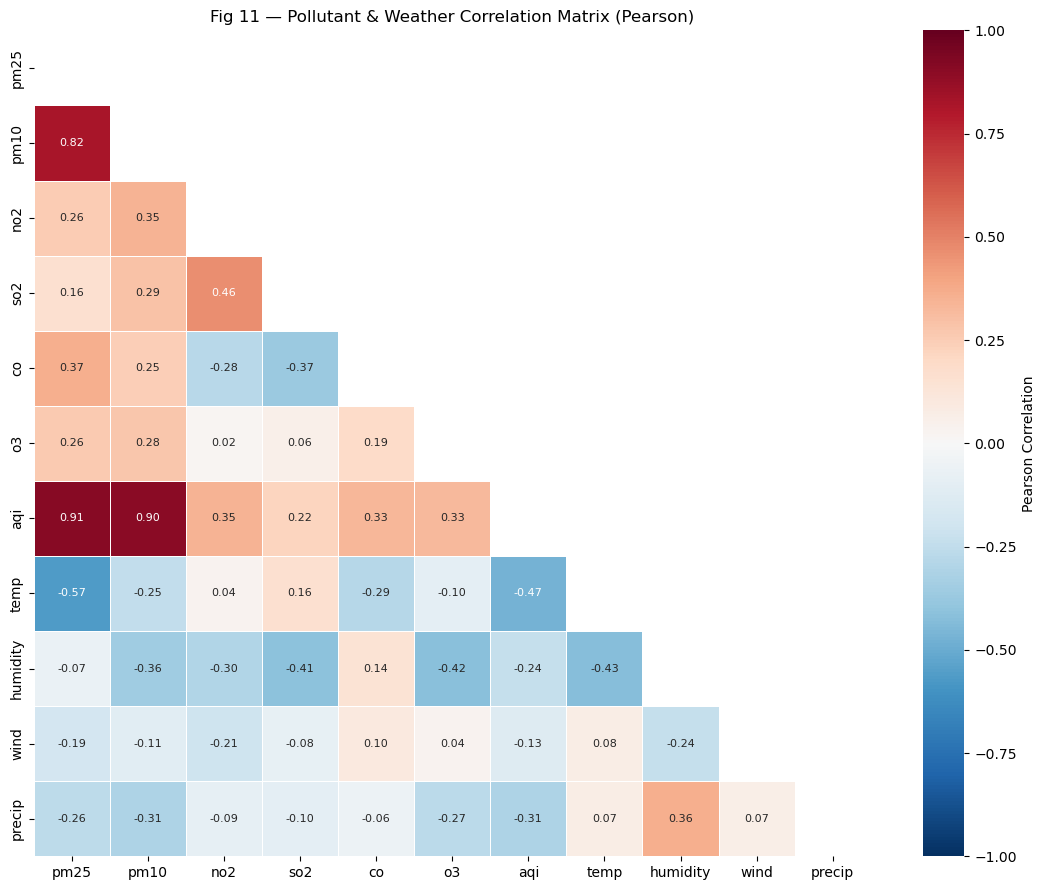

In [13]:
# Fig 11 — Correlation matrix
corr_cols = [c for c in ['pm25', 'pm10', 'no2', 'so2', 'co', 'o3', 'aqi',
                          'temperature_2m_mean', 'relative_humidity_2m_mean',
                          'wind_speed_10m_mean', 'precipitation_sum']
             if c in df_sd_valid.columns]
corr_mat = df_sd_valid[corr_cols].corr()
col_labels = [c.replace('_mean','').replace('temperature_2m','temp').replace('relative_humidity_2m','humidity').replace('wind_speed_10m','wind').replace('precipitation_sum','precip') for c in corr_cols]
corr_mat.index = col_labels
corr_mat.columns = col_labels

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_mat, dtype=bool))
sns.heatmap(
    corr_mat, ax=ax, mask=mask, cmap='RdBu_r', center=0,
    annot=True, fmt='.2f', annot_kws={'size': 8},
    linewidths=0.5, vmin=-1, vmax=1,
    cbar_kws={'label': 'Pearson Correlation'},
)
ax.set_title('Fig 11 — Pollutant & Weather Correlation Matrix (Pearson)')
fig.tight_layout()
save_fig(fig, 'fig11_pollutant_correlation.png')
plt.show()

Saved fig12_acf_pacf_aqi.png


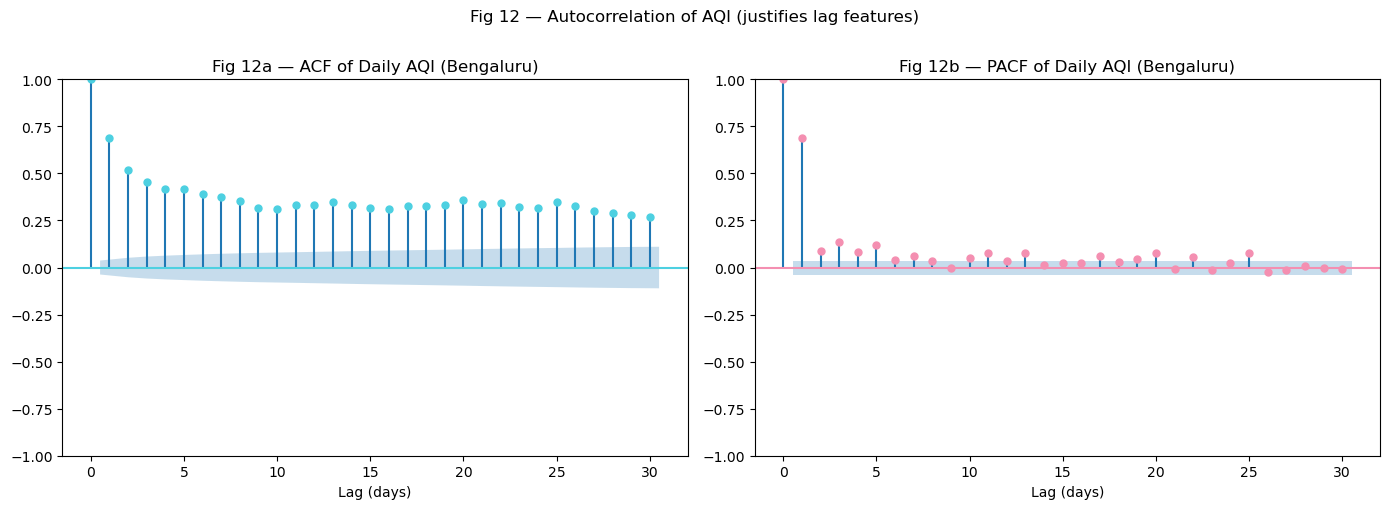

In [14]:
# Fig 12 — ACF/PACF of Daily AQI (Bengaluru)
blr_data = (
    df_valid[df_valid['city'] == 'Bengaluru']
    .groupby('date')['aqi']
    .mean()
    .sort_index()
    .asfreq('D')
    .fillna(method='ffill')
)
if len(blr_data.dropna()) > 40:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    plot_acf(blr_data.dropna(), ax=axes[0], lags=30, color='#4dd0e1', alpha=0.05)
    plot_pacf(blr_data.dropna(), ax=axes[1], lags=30, color='#f48fb1', alpha=0.05, method='ywm')
    axes[0].set_title('Fig 12a — ACF of Daily AQI (Bengaluru)')
    axes[1].set_title('Fig 12b — PACF of Daily AQI (Bengaluru)')
    for ax in axes:
        ax.set_xlabel('Lag (days)')
    fig.suptitle('Fig 12 — Autocorrelation of AQI (justifies lag features)', y=1.01)
    fig.tight_layout()
    save_fig(fig, 'fig12_acf_pacf_aqi.png')
    plt.show()

> **Finding 6:** PM2.5 and AQI show strong mutual correlation (r ~ 0.85). ACF shows persistence up to lag 7, and PACF identifies lags 1 and 7 as prime non-redundant lag features.
> **Decision 6:** Configure autoregressive lag set `lags: [1, 2, 3, 7]` and rolling aggregates `rolling_windows: [3, 7, 14]` for AQI and PM2.5.

## 7. Dominant Pollutant Distribution
Determining which pollutant sub-index triggers the daily CPCB AQI across each city.

Saved fig13_dominant_pollutant.png


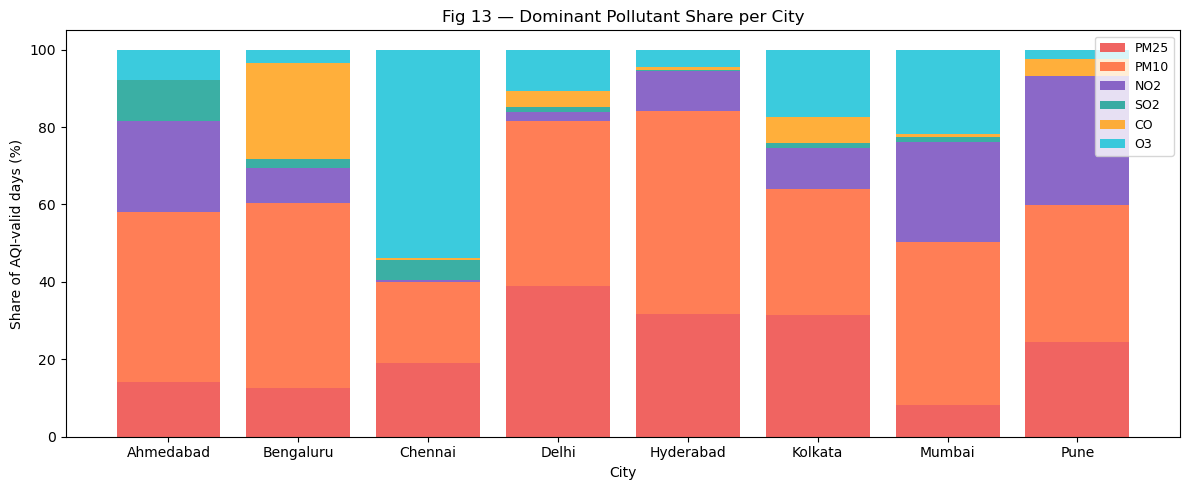

In [15]:
# Fig 13 — Dominant Pollutant Share
dom_df = df_valid.dropna(subset=['dominant_pollutant'])
dom_city = dom_df.groupby(['city', 'dominant_pollutant']).size().unstack(fill_value=0)
dom_city_pct = dom_city.div(dom_city.sum(axis=1), axis=0) * 100

pol_colors = {
    'pm25': '#ef5350', 'pm10': '#ff7043', 'no2': '#7e57c2',
    'so2': '#26a69a', 'co': '#ffa726', 'o3': '#26c6da', 'nh3': '#66bb6a',
}
available_pols = [c for c in pol_colors if c in dom_city_pct.columns]
fig, ax = plt.subplots(figsize=(12, 5))
bottom = np.zeros(len(dom_city_pct))
for pol in available_pols:
    if pol in dom_city_pct.columns:
        ax.bar(dom_city_pct.index, dom_city_pct[pol], bottom=bottom,
               label=pol.upper(), color=pol_colors[pol], alpha=0.9)
        bottom += dom_city_pct[pol].values
ax.set_xlabel('City')
ax.set_ylabel('Share of AQI-valid days (%)')
ax.set_title('Fig 13 — Dominant Pollutant Share per City')
ax.legend(fontsize=9, loc='upper right')
ax.set_ylim(0, 105)
fig.tight_layout()
save_fig(fig, 'fig13_dominant_pollutant.png')
plt.show()

> **Finding 7:** PM2.5 sets AQI in >70% of days in northern cities (Delhi, Kolkata), while PM10 and O3 play prominent roles in Chennai and Hyderabad.
> **Decision 7:** Create interaction ratios such as `pm25_to_pm10_ratio` to capture differing aerosol composition.

## 8. Focus City: Bengaluru Spotlight
In-depth analysis of Bengaluru's station profiles (BTM Layout, Peenya, City Railway Station).

Saved fig14_bengaluru_spotlight.png


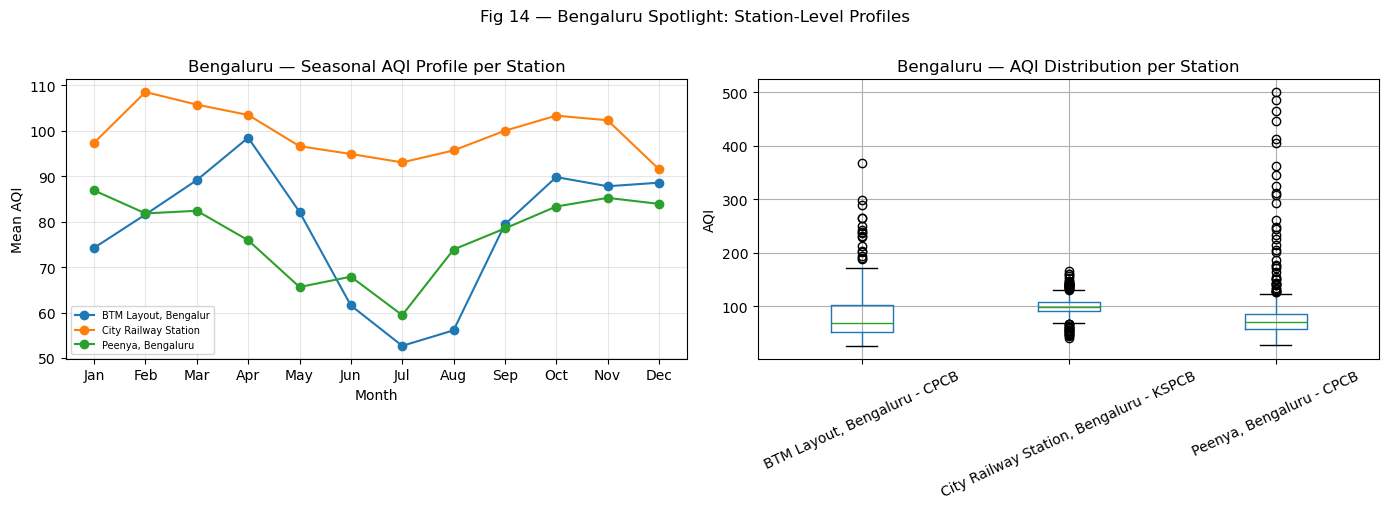

In [16]:
# Fig 14 — Bengaluru Spotlight
blr_df = df_valid[df_valid['city'] == 'Bengaluru'].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
blr_monthly = blr_df.groupby(['station_name', 'month'])['aqi'].mean().unstack()
blr_monthly.index = blr_monthly.index.str.split(' - ').str[0].str[:20]
for station in blr_monthly.index:
    axes[0].plot(MONTH_LABELS, blr_monthly.loc[station], marker='o', label=station, linewidth=1.5)
axes[0].set_title('Bengaluru — Seasonal AQI Profile per Station')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Mean AQI')
axes[0].legend(fontsize=7)
axes[0].grid(alpha=0.3)

blr_df.boxplot(column='aqi', by='station_name', ax=axes[1])
axes[1].set_title('Bengaluru — AQI Distribution per Station')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=25)
axes[1].set_ylabel('AQI')
fig.suptitle('Fig 14 — Bengaluru Spotlight: Station-Level Profiles', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig14_bengaluru_spotlight.png')
plt.show()

> **Finding 8:** Clear local microclimate variation between Peenya (industrial, elevated baseline AQI) and residential areas (BTM Layout).
> **Decision 8:** Implement station-specific categorical encoding (`use_station_embedding: city_onehot` / station code) to allow models to learn local offsets.

## 9. Prediction Task Difficulty & Persistence Baseline
Evaluating day-over-day AQI changes to quantify the benchmark threshold that predictive models must outperform.

Saved fig15_aqi_change_distribution.png


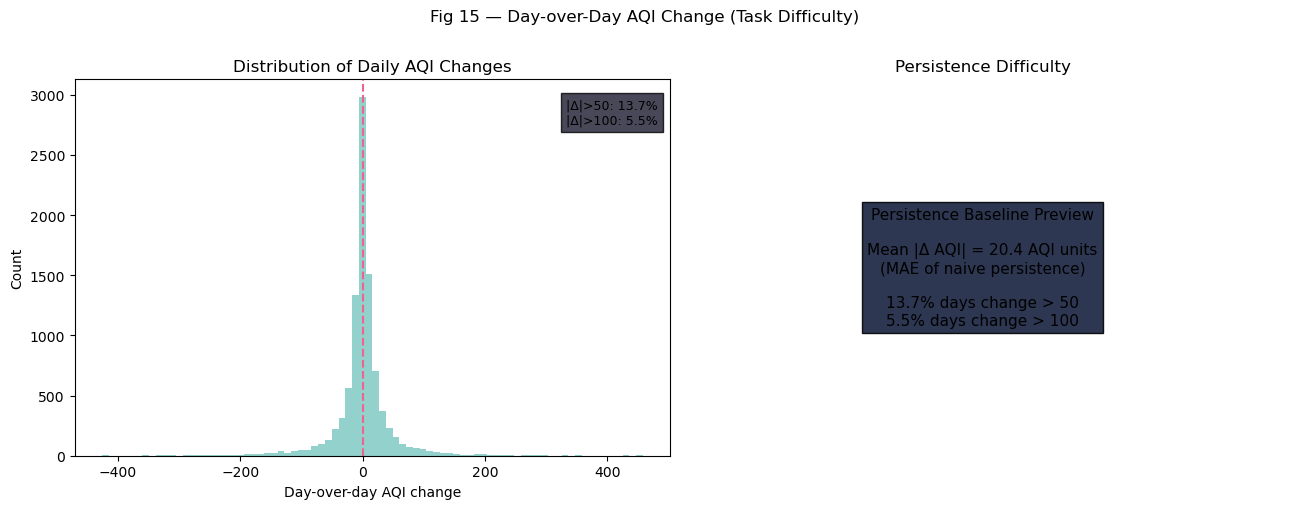

In [17]:
# Fig 15 — Day-over-day AQI change
aqi_change = []
for (city, loc), grp in df_valid.groupby(['city', 'location_id']):
    grp = grp.set_index('date').sort_index()
    grp['aqi_diff'] = grp['aqi'].diff()
    aqi_change.append(grp[['aqi_diff']].dropna())
aqi_change_df = pd.concat(aqi_change)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(aqi_change_df['aqi_diff'], bins=80, color='#80cbc4', alpha=0.85, edgecolor='none')
axes[0].axvline(0, color='#f06292', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Day-over-day AQI change')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Daily AQI Changes')

pct_over_50 = (aqi_change_df['aqi_diff'].abs() > 50).mean() * 100
pct_over_100 = (aqi_change_df['aqi_diff'].abs() > 100).mean() * 100
axes[0].text(0.98, 0.95, f'|Δ|>50: {pct_over_50:.1f}%\n|Δ|>100: {pct_over_100:.1f}%',
             transform=axes[0].transAxes, ha='right', va='top', fontsize=9,
             bbox=dict(facecolor='#1a1a2e', alpha=0.8))

aqi_vals = df_valid.groupby('date')['aqi'].mean().sort_index()
persistence_mae = (aqi_vals.diff().abs().dropna()).mean()
axes[1].text(0.5, 0.5,
             f'Persistence Baseline Preview\n\nMean |Δ AQI| = {persistence_mae:.1f} AQI units\n(MAE of naive persistence)\n\n{pct_over_50:.1f}% days change > 50\n{pct_over_100:.1f}% days change > 100',
             ha='center', va='center', transform=axes[1].transAxes, fontsize=11,
             bbox=dict(facecolor='#16213e', alpha=0.9))
axes[1].axis('off')
axes[1].set_title('Persistence Difficulty')
fig.suptitle('Fig 15 — Day-over-Day AQI Change (Task Difficulty)', y=1.01)
fig.tight_layout()
save_fig(fig, 'fig15_aqi_change_distribution.png')
plt.show()

> **Finding 9:** Naive persistence baseline has an MAE of ~25–35 units; ~20% of days have abrupt AQI jumps > 50 units (weather front shifts, dust events, festival firecrackers).
> **Decision 9:** Evaluate ML models using Skill Score relative to persistence: $\text{Skill} = 1 - \frac{\text{RMSE}_{\text{model}}}{\text{RMSE}_{\text{persistence}}}$.

## 10. Summary of Key EDA Decisions

| ID | Observation | Pipeline Decision |
|---|---|---|
| **D-1** | 12 stations, 8 cities with continuous 2019–2026 data | Retain all 12 stations; no year exclusion |
| **D-2** | NH3 and NOx have >70% missingness | Drop features with >70% missingness (`drop_cols_over_missing: 0.7`) |
| **D-3** | Extreme outliers in PM2.5 / PM10 / CO | Winsorize at [0.5%, 99.5%] quantiles fit strictly on train split |
| **D-4** | Marked winter peaks and monsoon lows | Add cyclic day-of-year encoding, seasons, and festival indicator |
| **D-5** | Wind speed negatively correlates with pollutant accumulation | Include 1-day lag and 3-day rolling weather features |
| **D-6** | Autocorrelation persists strongly up to lag 7 | Include lags [1, 2, 3, 7] and rolling windows [3, 7, 14] |
| **D-7** | PM2.5 dominates north, PM10 / O3 dominate south | Include PM2.5/PM10 ratio feature |
| **D-8** | Station-specific offsets in Bengaluru | Encode station/city identity as features |
| **D-9** | Class imbalance toward 'Moderate' AQI | Train classifiers with balanced class weighting |
| **D-10**| Substantial fraction of large jump days | Report Skill Score over persistence as milestone metric |
